<div class="dark-title" style="background:linear-gradient(90deg,#1e3a8a,#5b21b6); color:#f1f5f9; padding:20px 32px; border-radius:8px; width:97%;"><style>.dark-title strong{color:#fde047;}</style>

## 📁 文件系统：从「注意力开关」到 Backend 分层

**一句话定位**：文件 ≠ 数据库，文件 = **LLM 的注意力开关**（写出去 = 暂时忘掉，读回来 = 想起来）。本课把 dict 塞进 state；deepagents 0.7 把它抽象成 **工具面不变 + Backend 可换**。
> 对应主课 `2_a_🔥_files.ipynb` + 新课 m2 / m3.1。本机 deepagents 0.7.28 实测。

</div>

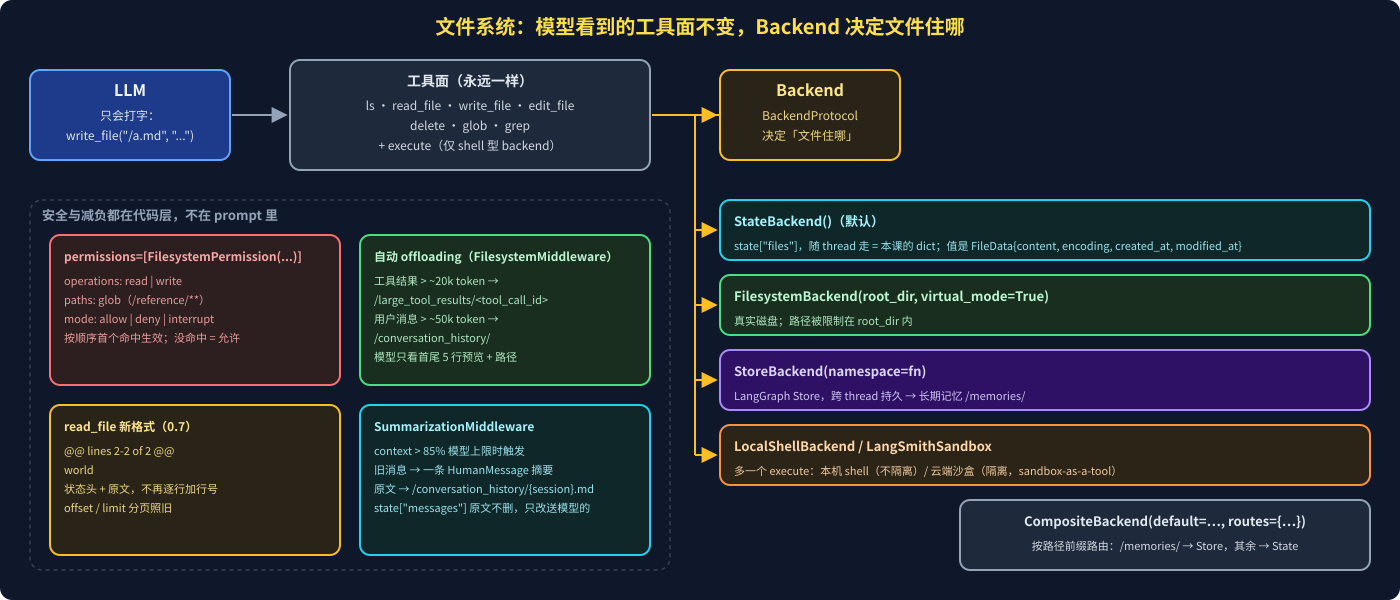

In [ ]:
from IPython.display import SVG
SVG(filename="assets/03_filesystem_backends.svg")

### 1️⃣ 为什么要文件：context offloading

| 场景 | 做法 |
|---|---|
| 工具产出大块文本（网页原文、SQL 导出） | **落盘 + 只回摘要/路径**，主 agent 按需 `read_file` |
| 想让 LLM 暂时忘掉某段长内容 | `write_file` 把它移出 messages，只留文件名 |
| 想让 LLM 想起 | `read_file` 把它塞回 messages **末尾** |
| 子 agent 的成果 | 写文件，只把「轻引用」传回协调者 → 杜绝「传话游戏」式衰减（Anthropic multi-agent research） |

经典套路 **Save → Search → Read-Back**：先把用户请求存盘，研究完再读回来，确保最终回答直接对准原问题。

### 2️⃣ 本课实现：dict + merge reducer

In [ ]:
from typing import Annotated, NotRequired

from langchain.agents import AgentState


def file_reducer(left: dict | None, right: dict | None) -> dict:
    if left is None:
        return right
    if right is None:
        return left
    return {**left, **right}            # 同名 key：right 覆盖 left


class DeepAgentState(AgentState):
    files: Annotated[NotRequired[dict[str, str]], file_reducer]   # 路径 → 内容

<div class="dark-warning" style="background:#2a2418; color:#fde68a; padding:12px 24px; border-left:4px solid #fbbf24; border-radius:4px; width:97%;"><style>.dark-warning strong{color:#f9a8d4;}</style>

**reducer 什么时候才真的需要**（被反复问的点）

- 单线程顺序写：`write_file` 自己「读旧 dict + 加新 key + 返回完整 dict」，默认覆盖和 merge **结果相同**。
- 必需的两个场景：① LLM 一次发多个 `write_file` → ToolNode **并行**执行，各自读到同一快照，默认覆盖会丢；② **子 agent** 把 files 提交回父 state，父 files + 子 files 必须合并。
- 库的做法：`FilesystemState.files` 用 `DeltaChannel(_file_data_delta_reducer, snapshot_frequency=50)`，语义相同（右覆盖；`None` = 删除），但 checkpoint 存**增量**，体积 O(N²) → O(N)。

</div>

### 3️⃣ 库的工具面（模型看到的，与 backend 无关）

| 工具 | 作用 | 备注 |
|---|---|---|
| `ls` `glob` `grep` | 找文件 / 按内容搜 | 都算 `read` 权限 |
| `read_file` | 读，支持 `offset / limit` | **0.7 新格式**：`@@ lines a-b of n @@` 状态头 + 原文，不再逐行加行号（evals：`edit_file` 出错 −15%，token −10%） |
| `write_file` `edit_file` `delete` | 写 / 精确替换 / 删除（递归、不可逆） | 都算 `write` 权限 |
| `execute` | 跑 shell 命令 | 只有 `LocalShellBackend` / 沙盒 backend 才有 |

state 里的值是 `FileData`，不是字符串：`{'/a.md': {'content': 'hello\nworld', 'encoding': 'utf-8', 'created_at': '…', 'modified_at': '…'}}`。
⚠️ 本课那种直接往 `state["files"]` 写 **str** 的自定义工具，和 0.7 的 `create_deep_agent` 混用会报 `TypeError: string indices must be integers`（本机实测）。预填文件请用 `agent.invoke({"messages": [...], "files": {...}})` 且值为 FileData 形状，或干脆让工具只返回文本、落盘交给库。

### 4️⃣ Backend 家族

In [ ]:
from pathlib import Path

from deepagents import FilesystemPermission, create_deep_agent
from deepagents.backends import CompositeBackend, FilesystemBackend, StateBackend, StoreBackend
from langchain.chat_models import init_chat_model
from langgraph.store.memory import InMemoryStore

model = init_chat_model("anthropic:claude-haiku-4-5")
store = InMemoryStore()


def memory_namespace(runtime):                      # 从运行时 context 决定命名空间 → 决定「谁看到哪份记忆」
    return ("memory", runtime.context["workspace_id"], runtime.context["user_id"])


agent = create_deep_agent(
    model=model,
    backend=CompositeBackend(
        default=StateBackend(),                                      # 普通草稿：随 thread
        routes={
            "/reference/": FilesystemBackend(root_dir=str(Path("reference")), virtual_mode=True),  # 真实磁盘
            "/memories/": StoreBackend(namespace=memory_namespace),  # 跨 thread 持久
        },
    ),
    store=store,
    permissions=[
        FilesystemPermission(operations=["write"], paths=["/reference/**"], mode="deny"),   # 只读参考资料
    ],
)

| Backend | 文件住哪 | 生命周期 | 典型用途 |
|---|---|---|---|
| `StateBackend()`（默认） | state 的 `files` 字段 | **单 thread**（有 checkpointer 才跨 invoke） | 草稿、中间结果 |
| `FilesystemBackend(root_dir, virtual_mode=True)` | 本地磁盘，路径限制在 `root_dir` | 磁盘 | 真实项目文件、skills 目录 |
| `StoreBackend(namespace=…)` | LangGraph `BaseStore` | **跨 thread** | 长期记忆 `/memories/` |
| `CompositeBackend(default, routes)` | 按前缀路由 | 取决于路由 | 把草稿和记忆分开 |
| `LocalShellBackend(root_dir)` | 本机 + `execute` | 磁盘 | 本地编程助手；**不隔离，不可用于生产** |
| `LangSmithSandbox(sandbox=…)` | 云端沙盒 + `execute` | 沙盒删除前 | 跑不可信代码；用 `try/finally` 删沙盒（计费资源） |

命名提醒：「agent 的文件系统」是能力（那 7 个工具），`FilesystemBackend` 只是其中一种实现。

### 5️⃣ 权限与工具裁剪（代码强制，模型绕不过）

| 机制 | 写法 | 规则 |
|---|---|---|
| 路径权限 | `permissions=[FilesystemPermission(operations=["read","write"], paths=["/research/**"], mode="allow"), FilesystemPermission(operations=["write"], paths=["/**"], mode="deny")]` | **按顺序首个命中生效**；没命中 = 允许；`mode="interrupt"` 交人审批 |
| 裁剪工具面 | `middleware=[FilesystemMiddleware(tools=["read_file", "grep", "ls"])]` | allowlist；`read_file` 必须保留 |
| 子 agent 权限 | `SubAgent["permissions"]` | 子 agent 自己的规则优先，否则继承父的 |

⚠️ 先写 `allow /**` 再写 `deny /secrets/**` → `/secrets/key.txt` **可读**（首个命中是 allow）。窄的 deny 放前面。

### 6️⃣ 自动减负：offloading 与 summarization

| 机制 | 触发 | 去哪 | 模型看到什么 |
|---|---|---|---|
| 工具结果 offloading（`FilesystemMiddleware`） | 单条 ToolMessage > ~20k token | `/large_tool_results/<tool_call_id>` | 首尾 5 行预览 + 路径，提示用 `read_file(offset, limit)` 分页 |
| 用户消息 offloading | 单条 HumanMessage > ~50k token | `/conversation_history/` | 同上 |
| `SummarizationMiddleware` | 总 token > 模型上限 **85%**（`trigger=("fraction", 0.85)` 可调） | 旧消息原文 → `/conversation_history/{session_id}.md` | 一条 HumanMessage 摘要（意图 / 关键事实 / 产物 / 下一步）+ 保留的近期消息 |

`ls/glob/grep/read_file/edit_file/write_file` 自身不被 offload（它们有内置截断或只回确认）。摘要**不改** `state["messages"]`，只改每轮**送给模型**的内容；触发后 state 里出现私有键 `_summarization_event`。演示时把 `model.profile["max_input_tokens"]` 调小即可看到（要传 model **对象**，传字符串会被重新初始化）。

### 7️⃣ shell / sandbox / interpreter —— 三种「让 agent 跑代码」

| | `execute`（shell 型 backend） | interpreter（`CodeInterpreterMiddleware`，`langchain-quickjs`） |
|---|---|---|
| 是什么 | backend 的一部分；跑任意 shell 命令 | **不是** backend；agent loop 里的一个 `eval` 工具，QuickJS 运行 JS |
| 能力 | 装包、跑脚本、测试、任意命令 | 只有 JS 标准库；无 fs / fetch / npm |
| 隔离 | `LocalShellBackend` 不隔离（`root_dir` 不限制 `execute`！）；沙盒隔离 | 嵌在进程内，靠 PTC allowlist 做边界 |
| 杀手锏 | — | **PTC（Programmatic Tool Calling）**：JS 里 `await tools.queryChinook({...})` 串联多次工具调用，中间结果**不进 LLM context**，只回最终字符串 |
| 用于 | 构建、文件 I/O、包 | 计算、循环、编排（包括 `task()` 动态派单） |

沙盒两种模式：**agent in sandbox**（API key 在沙盒里，改 agent 要重建镜像）vs **sandbox as a tool**（agent 在外，通过 `execute` 用沙盒；key 留在主机）—— 新课用后者。

<div class="dark-error" style="background:#2d1f1f; color:#fca5a5; padding:10px 24px; border-left:4px solid #f87171; border-radius:4px; width:97%;"><style>.dark-error strong{color:#fde047;}</style>

**坑**

| 坑 | 结果 |
|---|---|
| 往 `state["files"]` 写 str 再用库工具读 | `TypeError`（0.7 值是 FileData） |
| 用 `StateBackend` 在 thread A 写、thread B 读 | 读不到（随 thread 走） |
| `LocalShellBackend(virtual_mode=True)` 以为安全 | 只限制文件工具；`execute` 仍以主机权限跑任何路径 |
| 权限规则顺序写反 | 宽 allow 先命中，窄 deny 永远不生效 |
| `FilesystemMiddleware(tools=[...])` 漏掉 `read_file` | 不允许 |
| 沙盒没 `finally` 删 | 持续计费 |

</div>

<div class="dark-success" style="background:#1a2e1f; color:#bbf7d0; padding:10px 24px; border-left:4px solid #4ade80; border-radius:4px; width:97%;"><style>.dark-success strong{color:#fbbf24;}</style>

**✨ 一句话带走**：文件 = **注意力开关**；本课的 dict-in-state 就是库的默认 **`StateBackend`**；0.7 的要点是 **工具面固定、Backend 可换（State / Filesystem / Store / Composite / Shell / Sandbox）、权限按顺序首个命中、大结果自动落盘、历史超 85% 自动摘要**；记得值是 `FileData` 不是 str。

</div>